In [12]:
import numpy as np
import pandas as pd
import matplotlib as plot

In [13]:
df = pd.read_csv('flight_train.csv')

In [14]:
print(df.shape)
df.info()


(15589, 12)
<class 'pandas.DataFrame'>
RangeIndex: 15589 entries, 0 to 15588
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                15589 non-null  int64  
 1   airline           12500 non-null  str    
 2   flight            15589 non-null  str    
 3   source_city       15589 non-null  str    
 4   departure_time    15589 non-null  str    
 5   stops             15589 non-null  str    
 6   arrival_time      15589 non-null  str    
 7   destination_city  15589 non-null  str    
 8   flight_class      15589 non-null  str    
 9   duration          12494 non-null  float64
 10  days_left         15589 non-null  int64  
 11  price             15589 non-null  int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 1.4 MB


# data preprocessing

## 1st Round of preprocessing

In [15]:
'''The airline feature has only 12500 non-null entries out of 15589
Through observation we can see that the first two codes in the flight feature
might be related to the airline.
'''

df["prefix"] = df["flight"].str.strip().str.upper().str[:2]

known = df[df["airline"].notna() & df["prefix"].notna()]

# 1. How well does prefix determine airline?
per_prefix = known.groupby("prefix")["airline"].agg(
    n_airlines="nunique",
    top=lambda s: s.mode().iloc[0],
    purity=lambda s: s.value_counts(normalize=True).iloc[0],
)
print(per_prefix[per_prefix["n_airlines"] > 1])   # the real inconsistencies

# 2. Mapping from the most common airline per prefix
prefix_to_airline = per_prefix["top"].to_dict()

# 3. Fill missing airlines
missing = df["airline"].isna()
filled = df.loc[missing, "prefix"].map(prefix_to_airline)
print("Fillable:", filled.notna().sum(), "of", missing.sum())
print("Prefixes with no mapping:", df.loc[missing & filled.isna(), "prefix"].unique())

df.loc[missing, "airline"] = filled

Empty DataFrame
Columns: [n_airlines, top, purity]
Index: []
Fillable: 3089 of 3089
Prefixes with no mapping: <StringArray>
[]
Length: 0, dtype: str


In [16]:

''' above we proved that the flight code (first two symbols) are related to the airline
    hence we fill in those information

    But this is also mean that 
    AIRLINE DO NOT GIVE ME ANYTHING NEW, it is a redundent feature. 

    But at the same time flight have a four digit number after the airline code so 
    untill we can deduce that we will keep both features as is.
'''

mask = df["airline"].isna()

df.loc[mask, "airline"] = (
    df.loc[mask, "flight"].str[:2].map(prefix_to_airline)
)

print("Remaining missing airlines:", df["airline"].isna().sum())
df.info()


Remaining missing airlines: 0
<class 'pandas.DataFrame'>
RangeIndex: 15589 entries, 0 to 15588
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                15589 non-null  int64  
 1   airline           15589 non-null  str    
 2   flight            15589 non-null  str    
 3   source_city       15589 non-null  str    
 4   departure_time    15589 non-null  str    
 5   stops             15589 non-null  str    
 6   arrival_time      15589 non-null  str    
 7   destination_city  15589 non-null  str    
 8   flight_class      15589 non-null  str    
 9   duration          12494 non-null  float64
 10  days_left         15589 non-null  int64  
 11  price             15589 non-null  int64  
 12  prefix            15589 non-null  str    
dtypes: float64(1), int64(3), str(9)
memory usage: 1.5 MB


In [17]:
'''Next is duration where we have only 12494 entries.
there are various way to deal with this without dropping the null values which
are substantial in numbers.

First is to just assume the average/mean and fill the values but we will do that
when all else fail.

First we will try to obtain the duration using other features.
'''
data = df.dropna(subset=["duration"]).copy()

print(
    "Duration-price correlation:",
    data["duration"].corr(data["price"])
)

# Reproducible 80/20 split
rng = np.random.default_rng(42)
indices = rng.permutation(data.index)

cut = int(0.8 * len(indices))
reference = data.loc[indices[:cut]]
validation = data.loc[indices[cut:]]

# Use the current feature names
group_cols = [
    "flight",
    "source_city",
    "destination_city",
    "stops"
]

# Learn medians from reference data only
group_medians = reference.groupby(group_cols)["duration"].median()

# Predict validation durations
keys = pd.MultiIndex.from_frame(validation[group_cols])
pred_group = pd.Series(
    keys.map(group_medians),
    index=validation.index
)

# Evaluate records whose combinations were seen in reference data
mask = pred_group.notna()
errors = validation.loc[mask, "duration"] - pred_group[mask]

print("Coverage:", round(mask.mean() * 100, 2), "%")
print("MAE:", round(errors.abs().mean(), 3), "hours")
print("RMSE:", round(np.sqrt((errors ** 2).mean()), 3), "hours")

Duration-price correlation: 0.6993828909536305
Coverage: 95.76 %
MAE: 0.188 hours
RMSE: 1.383 hours


In [18]:
'''A correlation of 0.69938 means that the duration feature is important enough 
to not ignore entirely. 

And after trying different combinations, the combination of flight, source city and destination city 
give a 95.76% coverage for the know value, so right now that is the best
method to fill in the null values in duration.
'''
group_cols = ["flight", "source_city", "destination_city", "stops"]

# Calculate medians using rows with known durations
known = df.dropna(subset=["duration"])

# 1. Flight + route + stops
median1 = known.groupby(group_cols)["duration"].median()
keys1 = pd.MultiIndex.from_frame(df[group_cols])
fill1 = pd.Series(keys1.map(median1), index=df.index)

# 2. Route + stops
median2 = known.groupby(
    ["source_city", "destination_city", "stops"]
)["duration"].median()

keys2 = pd.MultiIndex.from_frame(
    df[["source_city", "destination_city", "stops"]]
)
fill2 = pd.Series(keys2.map(median2), index=df.index)

# 3. Route only
median3 = known.groupby(
    ["source_city", "destination_city"]
)["duration"].median()

keys3 = pd.MultiIndex.from_frame(
    df[["source_city", "destination_city"]]
)
fill3 = pd.Series(keys3.map(median3), index=df.index)

# Apply fallbacks only to missing values
missing = df["duration"].isna()
df.loc[missing, "duration"] = fill1[missing]
missing = df["duration"].isna()
df.loc[missing, "duration"] = fill2[missing]
missing = df["duration"].isna()
df.loc[missing, "duration"] = fill3[missing]

# Final fallback: global median
df["duration"] = df["duration"].fillna(known["duration"].median())

print("Remaining missing durations:", df["duration"].isna().sum())
df.info()

Remaining missing durations: 0
<class 'pandas.DataFrame'>
RangeIndex: 15589 entries, 0 to 15588
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                15589 non-null  int64  
 1   airline           15589 non-null  str    
 2   flight            15589 non-null  str    
 3   source_city       15589 non-null  str    
 4   departure_time    15589 non-null  str    
 5   stops             15589 non-null  str    
 6   arrival_time      15589 non-null  str    
 7   destination_city  15589 non-null  str    
 8   flight_class      15589 non-null  str    
 9   duration          15589 non-null  float64
 10  days_left         15589 non-null  int64  
 11  price             15589 non-null  int64  
 12  prefix            15589 non-null  str    
dtypes: float64(1), int64(3), str(9)
memory usage: 1.5 MB


In [19]:
print("ID-price correlation:", df["id"].corr(df["price"]))

'''First we remove id since that provides nothing to do with the price
as common sense and the correlation between them indicates.
'''

df = df.drop(columns = ["id"])

ID-price correlation: 0.0023720173042834614


In [20]:
'''We know we can obtain the airline info from the flight feature
so having an extra feature adds nothing to the learning.
'''

df = df.drop(columns = ["airline"])

In [21]:
'''flight is interesting, we can obtain the airline data from the first two 
codes of it, and then use it with two other features to somewhat guess the
duration of the flight.
'''
# 1. Unique full flight codes
print("Unique flight codes:", df["flight"].nunique())

# 2. Unique first two characters (airline prefix)
prefix = df["flight"].str[:2]
print("Unique two-character prefixes:", prefix.nunique())

# 3. Unique flight numbers (part after the prefix)
number = df["flight"].str[2:].str.strip()
print("Unique flight numbers:", number.nunique())

# df["flight_prefix"] = df["flight"].str[:2]
df["flight_number"] = df["flight"].str[2:].str.strip()

df = df.drop(columns=["flight"])
df.info()

Unique flight codes: 1070
Unique two-character prefixes: 19
Unique flight numbers: 1014
<class 'pandas.DataFrame'>
RangeIndex: 15589 entries, 0 to 15588
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   source_city       15589 non-null  str    
 1   departure_time    15589 non-null  str    
 2   stops             15589 non-null  str    
 3   arrival_time      15589 non-null  str    
 4   destination_city  15589 non-null  str    
 5   flight_class      15589 non-null  str    
 6   duration          15589 non-null  float64
 7   days_left         15589 non-null  int64  
 8   price             15589 non-null  int64  
 9   prefix            15589 non-null  str    
 10  flight_number     15589 non-null  str    
dtypes: float64(1), int64(2), str(8)
memory usage: 1.3 MB


In [22]:
'''

Now we deal with the string values in the dataset.
There are various methods, 

'''

'''Source city one hot encoding
'''

df = pd.get_dummies(df, columns=["source_city"], dtype=int)

'''Departure time
'''
# print(df["departure_time"].value_counts())
df = pd.get_dummies(df, columns=["departure_time"], dtype=int)

'''Arrival time
'''

df = pd.get_dummies(df, columns=["arrival_time"], dtype=int)

'''stops
'''
# print(df["stops"].value_counts())
stops_map = {
    "zero": 0,
    "one": 1,
    "two_or_more": 2
}

df["stops"] = df["stops"].map(stops_map)

'''Desination city
'''

df = pd.get_dummies(df, columns=["destination_city"], dtype=int)

'''Flight class
'''
# print(df["flight_class"].value_counts())
df["flight_class"] = df["flight_class"].map({
    "Economy": 0,
    "Business": 1
})

df = pd.get_dummies(df, columns=["prefix"], dtype=int)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15589 entries, 0 to 15588
Data columns (total 49 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   stops                         15589 non-null  int64  
 1   flight_class                  15589 non-null  int64  
 2   duration                      15589 non-null  float64
 3   days_left                     15589 non-null  int64  
 4   price                         15589 non-null  int64  
 5   flight_number                 15589 non-null  str    
 6   source_city_Gotham            15589 non-null  int64  
 7   source_city_Hill Valley       15589 non-null  int64  
 8   source_city_Los Santos        15589 non-null  int64  
 9   source_city_Metropolis        15589 non-null  int64  
 10  source_city_Night City        15589 non-null  int64  
 11  source_city_Springfield       15589 non-null  int64  
 12  departure_time_Afternoon      15589 non-null  int64  
 13  departure_ti

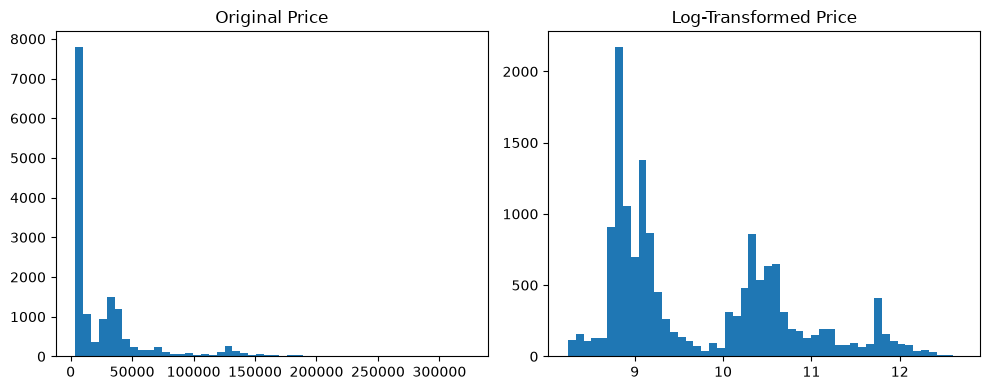

In [23]:
'''price to log(price) to reduce the skew
'''
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df["price"], bins=50)
plt.title("Original Price")

plt.subplot(1, 2, 2)
plt.hist(np.log1p(df["price"]), bins=50)
plt.title("Log-Transformed Price")

plt.tight_layout()
plt.show()

df["price"] = np.log1p(df["price"])

In [24]:
'''Now due to the nature of city1 -> city2 having different price than city2 -> city1 
hence keeping the cities different with seperate hot-keys
'''

source_cols = df.filter(regex=r"^source_city_").columns
dest_cols = df.filter(regex=r"^destination_city_").columns

df["source_city"] = (
    df[source_cols].idxmax(axis=1).str.replace("source_city_", "", regex=False)
)

df["destination_city"] = (
    df[dest_cols].idxmax(axis=1).str.replace(
        "destination_city_", "", regex=False
    )
)

df["route"] = df["source_city"] + "_to_" + df["destination_city"]

df = df.drop(columns=list(source_cols) + list(dest_cols))
df = pd.get_dummies(df, columns=["route"], dtype=int)
df = df.drop(columns=["source_city", "destination_city"])

df

,stops,flight_class,duration,days_left,price,flight_number,departure_time_Afternoon,departure_time_Early_Morning,departure_time_Evening,departure_time_Late_Night,...,route_Night City_to_Gotham,route_Night City_to_Hill Valley,route_Night City_to_Los Santos,route_Night City_to_Metropolis,route_Night City_to_Springfield,route_Springfield_to_Gotham,route_Springfield_to_Hill Valley,route_Springfield_to_Los Santos,route_Springfield_to_Metropolis,route_Springfield_to_Night City
0,0,0,2.92,18,9.094930,1070,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,1.33,38,8.540128,285,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,2.08,13,10.470164,2641,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
3,0,0,2.25,5,8.773075,6704,1,0,0,0,...,0,0,0,1,0,0,0,0,0,0
4,1,0,4.83,21,8.830982,234,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15584,0,1,2.92,39,10.958252,2471,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
15585,0,1,2.50,27,10.342516,2776,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
15586,0,0,2.92,19,9.280612,6515,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
15587,0,0,2.25,9,8.768108,449,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


In [25]:
'''Dropping the flight_number for now
'''
df = df.drop(columns=["flight_number"])

'''After dropping flight number we get more duplicate data
'''
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(14431, 66)


In [26]:
df.to_csv("1stRoundFlightdata.csv", index=False)